# Session Title: Artificial Netural Networks for classification

**Instructor:** Zahra Sadeghi

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# ==========================================
# 1. GENERATE THE DATASET
# ==========================================

In [ ]:
X, y = make_moons(
    n_samples=300,
    noise=0.20,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ==========================================
# 2. VISUALIZE THE ORIGINAL DATA
# ==========================================

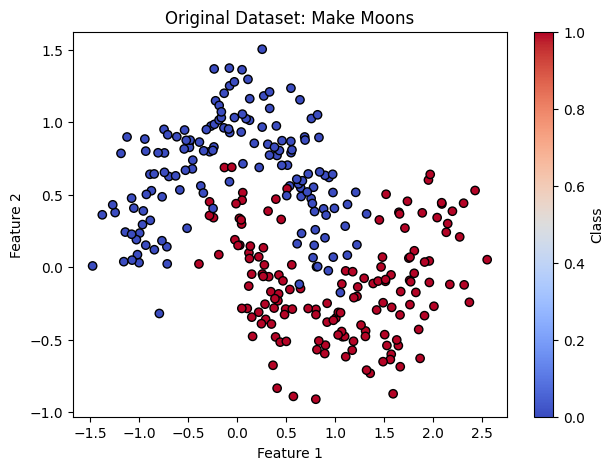

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Dataset: Make Moons")
plt.colorbar(label="Class")
plt.show()

# ==========================================
# 4. TRAIN MLP WITH DIFFERENT LEARNING RATES
# ==========================================

In [ ]:
learning_rates = [0.001, 0.01, 0.1]

models = {}
losses = {}

for lr in learning_rates:

    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(10, 10),
            activation="relu",
            solver="adam",
            learning_rate_init=lr,
            max_iter=1000,
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    # Access the trained MLP inside the pipeline
    mlp = model.named_steps["mlpclassifier"]

    models[lr] = model
    losses[lr] = mlp.loss_curve_

    predictions = model.predict(X_test)

    print(f"Learning rate: {lr}")
    print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")
    print(f"Training iterations: {mlp.n_iter_}")
    print("-" * 35)

Learning rate: 0.001
Test accuracy: 0.917
Training iterations: 830
-----------------------------------
Learning rate: 0.01
Test accuracy: 0.900
Training iterations: 197
-----------------------------------
Learning rate: 0.1
Test accuracy: 0.883
Training iterations: 78
-----------------------------------


# ==========================================
# 5. VISUALIZE TRAINING LOSS
# ==========================================

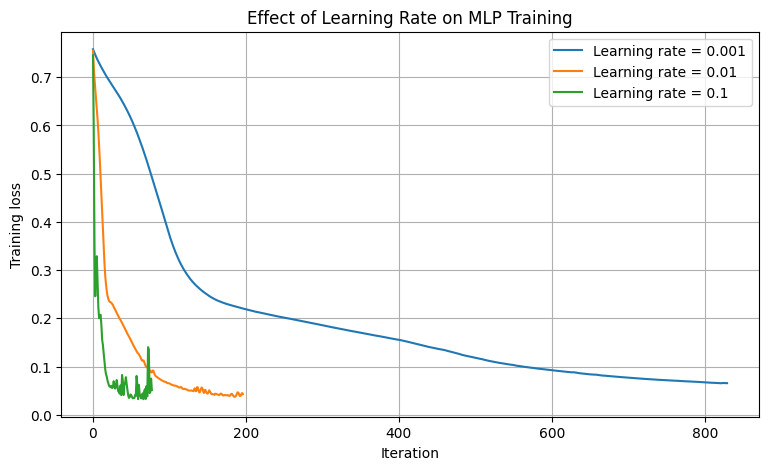

In [ ]:
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    plt.plot(
        losses[lr],
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("Effect of Learning Rate on MLP Training")
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# 6. VISUALIZE DECISION BOUNDARIES
# ==========================================

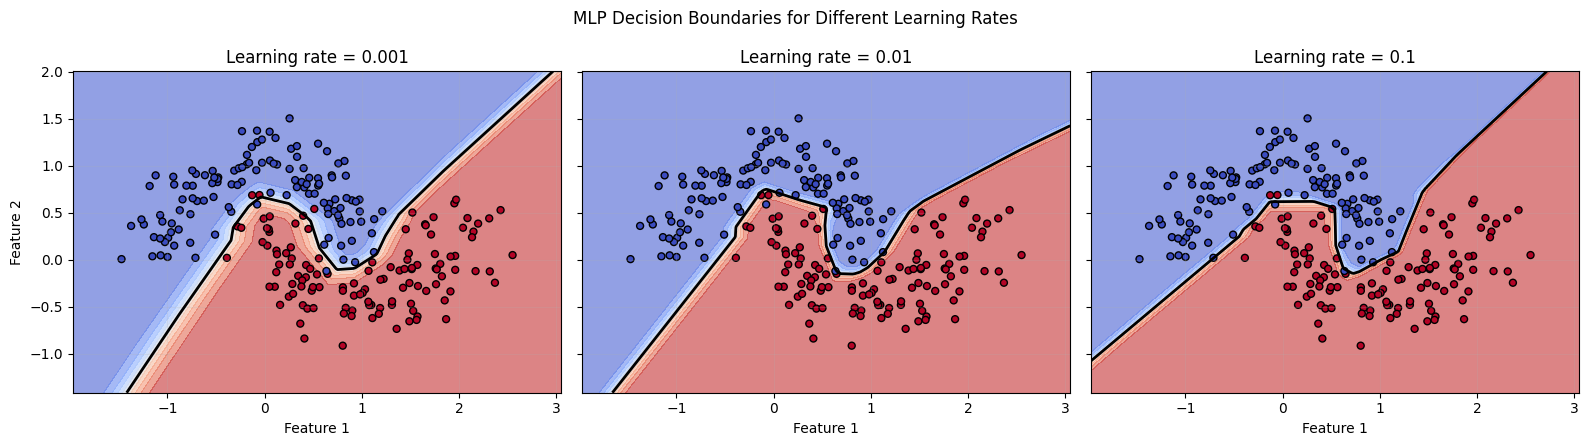

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    sharex=True,
    sharey=True
)

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, lr in zip(axes, learning_rates):

    model = models[lr]

    probabilities = model.predict_proba(grid)[:, 1]
    Z = probabilities.reshape(xx.shape)

    # Predicted probability regions
    ax.contourf(
        xx, yy, Z,
        levels=np.linspace(0, 1, 11),
        cmap="coolwarm",
        alpha=0.6
    )

    # Decision boundary at probability 0.5
    ax.contour(
        xx, yy, Z,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    # Training data
    ax.scatter(
        X_train[:, 0],
        X_train[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    ax.set_title(f"Learning rate = {lr}")
    ax.set_xlabel("Feature 1")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Feature 2")

fig.suptitle("MLP Decision Boundaries for Different Learning Rates")
plt.tight_layout()
plt.show()

* Learning rate = 0.001: Updates may be small, leading to slower learning.
* Learning rate = 0.01: May provide a good balance between speed and stability.
* Learning rate = 0.1: Updates are larger, which may speed up learning or make it less stable.